# Soil Fertility Classification Using Machine Learning
**PBL Project | Jupyter Notebook**

This notebook follows the workflow: Data Understanding → Cleaning → EDA → Visualization → Correlation → Feature Selection → Model Training → Evaluation → Interpretation → Prediction.

> **Dataset limitation:** This is source-calibrated synthetic teaching data (1,000 rows), not 1,000 authentic laboratory observations. `Fertility_Class` is a derived label based on a score, not an original measured label. Treat results as educational, not agricultural advice.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

## 2. Load Dataset
Place the CSV file in the same folder as this notebook. Update the path if needed.

In [2]:
df = pd.read_csv("soil_fertility_classification_1000.csv")
df.head()

,Sample_ID,Source_Calibration,State,District,Soil_Type,Crop,pH,Electrical_Conductivity_dS_m,Organic_Carbon_g_kg,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Sulphur_mg_kg,Zinc_mg_kg,Boron_mg_kg,Iron_mg_kg,Manganese_mg_kg,Copper_mg_kg,Fertility_Score,Fertility_Class
0,SFC-0001,Indian laboratory soil datasets (AgriNet/Krish...,Uttar Pradesh,Lucknow,Alluvial,Cotton,6.91,0.150,12.08,169.90,32.32,54.05,15.46,1.34,1.13,16.65,7.20,1.00,47.15,Medium Fertility
1,SFC-0002,Indian laboratory soil dataset calibrated exte...,Maharashtra,Nashik,Red,Cotton,6.61,0.424,10.85,170.47,31.70,126.62,11.17,0.87,1.39,15.67,6.15,1.36,46.47,Medium Fertility
2,SFC-0003,Indian laboratory soil dataset calibrated exte...,Karnataka,Mysuru,Loamy,Pulses,7.52,0.596,5.51,130.75,32.14,381.20,10.98,0.51,0.83,21.16,5.31,0.69,39.27,Low Fertility
3,SFC-0004,Indian laboratory soil dataset calibrated exte...,Punjab,Ludhiana,Clay Loam,Rice,7.03,0.257,9.48,202.66,49.68,77.23,20.79,0.76,1.60,38.51,9.07,0.60,59.38,Medium Fertility
4,SFC-0005,Indian laboratory soil datasets (AgriNet/Krish...,Uttar Pradesh,Bareilly,Loamy,Vegetables,7.17,0.282,15.65,189.12,24.58,213.50,17.32,1.35,0.47,25.92,17.15,1.20,61.00,Medium Fertility


## 3. Understand the Dataset

In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\\nColumn names:")
print(df.columns.tolist())

Rows: 1000
Columns: 20
\nColumn names:
['Sample_ID', 'Source_Calibration', 'State', 'District', 'Soil_Type', 'Crop', 'pH', 'Electrical_Conductivity_dS_m', 'Organic_Carbon_g_kg', 'Available_N_kg_ha', 'Available_P_kg_ha', 'Available_K_kg_ha', 'Sulphur_mg_kg', 'Zinc_mg_kg', 'Boron_mg_kg', 'Iron_mg_kg', 'Manganese_mg_kg', 'Copper_mg_kg', 'Fertility_Score', 'Fertility_Class']


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Sample_ID                     1000 non-null   object 
 1   Source_Calibration            1000 non-null   object 
 2   State                         1000 non-null   object 
 3   District                      1000 non-null   object 
 4   Soil_Type                     1000 non-null   object 
 5   Crop                          1000 non-null   object 
 6   pH                            1000 non-null   float64
 7   Electrical_Conductivity_dS_m  1000 non-null   float64
 8   Organic_Carbon_g_kg           1000 non-null   float64
 9   Available_N_kg_ha             1000 non-null   float64
 10  Available_P_kg_ha             1000 non-null   float64
 11  Available_K_kg_ha             1000 non-null   float64
 12  Sulphur_mg_kg                 1000 non-null   float64
 13  Zinc

In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Sample_ID,1000,1000,SFC-0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Source_Calibration,1000,2,Indian laboratory soil dataset calibrated exte...,509,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,1000,8,Uttar Pradesh,310,NaN,NaN,NaN,NaN,NaN,NaN,NaN
District,1000,18,Meerut,109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Soil_Type,1000,7,Alluvial,304,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop,1000,8,Groundnut,155,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pH,1000.0,NaN,NaN,NaN,6.97297,0.538233,5.65,6.61,6.97,7.34,8.12
Electrical_Conductivity_dS_m,1000.0,NaN,NaN,NaN,0.509072,0.298188,0.06,0.295,0.4495,0.64325,1.9
Organic_Carbon_g_kg,1000.0,NaN,NaN,NaN,7.73816,4.391373,1.51,4.705,6.59,9.7925,24.75
Available_N_kg_ha,1000.0,NaN,NaN,NaN,177.40929,43.067258,81.54,147.37,177.215,205.7525,305.93


In [6]:
print("Fertility class counts:")
display(df["Fertility_Class"].value_counts())

print("\\nClass percentages:")
display((df["Fertility_Class"].value_counts(normalize=True) * 100).round(2))

Fertility class counts:


,count
Fertility_Class,
Medium Fertility,596
Low Fertility,319
High Fertility,85


\nClass percentages:


,proportion
Fertility_Class,
Medium Fertility,59.6
Low Fertility,31.9
High Fertility,8.5


## 4. Data Cleaning

In [7]:
# Check and remove exact duplicate rows
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().copy()
print("Shape after duplicate removal:", df.shape)

# Review data types
display(df.dtypes)

Duplicate rows: 0
Shape after duplicate removal: (1000, 20)


,0
Sample_ID,object
Source_Calibration,object
State,object
District,object
Soil_Type,object
Crop,object
pH,float64
Electrical_Conductivity_dS_m,float64
Organic_Carbon_g_kg,float64
Available_N_kg_ha,float64


In [8]:
# Check categorical values for consistency (spaces and capitalization are not automatically altered)
categorical_cols = df.select_dtypes(include=["object", "category"]).columns
for col in categorical_cols:
    print(f"\\n{col}:")
    print(df[col].value_counts(dropna=False).head(20))

\nSample_ID:
Sample_ID
SFC-0001    1
SFC-0002    1
SFC-0003    1
SFC-0004    1
SFC-0005    1
SFC-0006    1
SFC-0007    1
SFC-0008    1
SFC-0009    1
SFC-0010    1
SFC-0011    1
SFC-0012    1
SFC-0013    1
SFC-0014    1
SFC-0015    1
SFC-0016    1
SFC-0017    1
SFC-0018    1
SFC-0019    1
SFC-0020    1
Name: count, dtype: int64
\nSource_Calibration:
Source_Calibration
Indian laboratory soil dataset calibrated extension                            509
Indian laboratory soil datasets (AgriNet/Krishnagiri/Dharmapuri calibrated)    491
Name: count, dtype: int64
\nState:
State
Uttar Pradesh     310
Tamil Nadu        181
Madhya Pradesh    119
Punjab            106
Bihar              85
West Bengal        81
Maharashtra        68
Karnataka          50
Name: count, dtype: int64
\nDistrict:
District
Meerut         109
Lucknow        106
Bareilly        95
Salem           65
Indore          63
Dharmapuri      59
Ludhiana        58
Krishnagiri     57
Bhopal          56
Patna           51
Nadia     

## 5. Missing Value Handling
Numerical columns are imputed with their median; categorical columns with their mode. If a column has no missing values, this operation leaves it unchanged.

In [9]:
missing_before = df.isna().sum()
display(missing_before[missing_before > 0])

numeric_cols_all = df.select_dtypes(include=np.number).columns
categorical_cols_all = df.select_dtypes(include=["object", "category"]).columns

for col in numeric_cols_all:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

for col in categorical_cols_all:
    if df[col].isna().any() and not df[col].mode().empty:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values remaining:", int(df.isna().sum().sum()))
display(df.isna().sum())

,0


Missing values remaining: 0


,0
Sample_ID,0
Source_Calibration,0
State,0
District,0
Soil_Type,0
Crop,0
pH,0
Electrical_Conductivity_dS_m,0
Organic_Carbon_g_kg,0
Available_N_kg_ha,0


## 6. Exploratory Data Analysis (EDA)

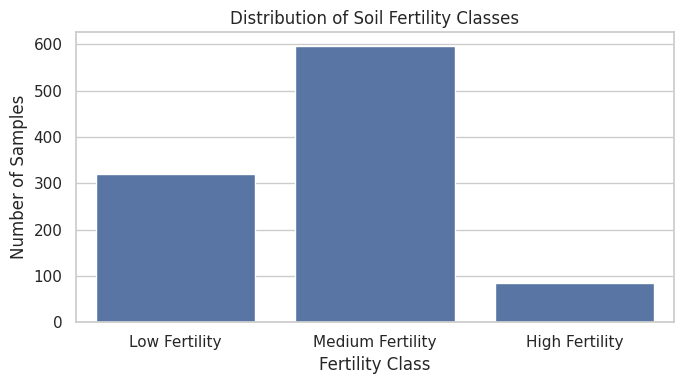

In [10]:
# Target class distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Fertility_Class", order=["Low Fertility", "Medium Fertility", "High Fertility"])
plt.title("Distribution of Soil Fertility Classes")
plt.xlabel("Fertility Class")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

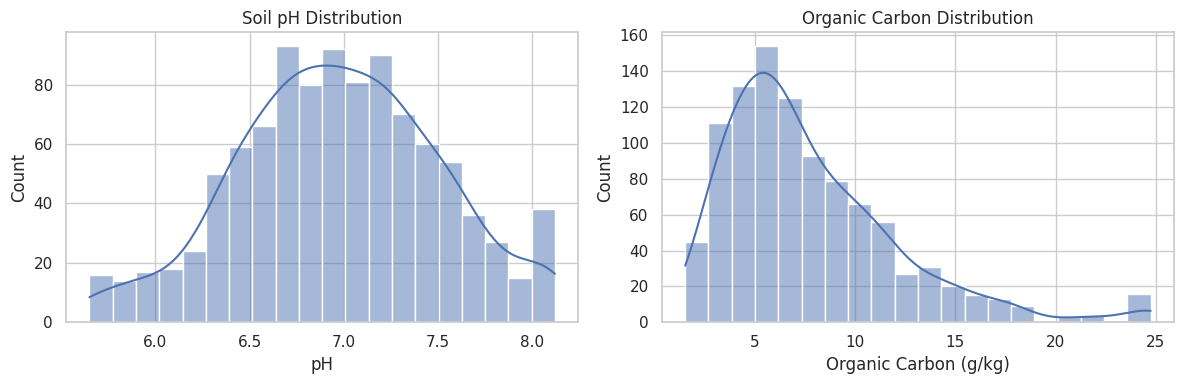

In [11]:
# Distribution of pH and Organic Carbon
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["pH"], bins=20, kde=True, ax=axes[0])
axes[0].set_title("Soil pH Distribution")
axes[0].set_xlabel("pH")
sns.histplot(df["Organic_Carbon_g_kg"], bins=20, kde=True, ax=axes[1])
axes[1].set_title("Organic Carbon Distribution")
axes[1].set_xlabel("Organic Carbon (g/kg)")
plt.tight_layout()
plt.show()

## 7. Visualization of Soil Parameters

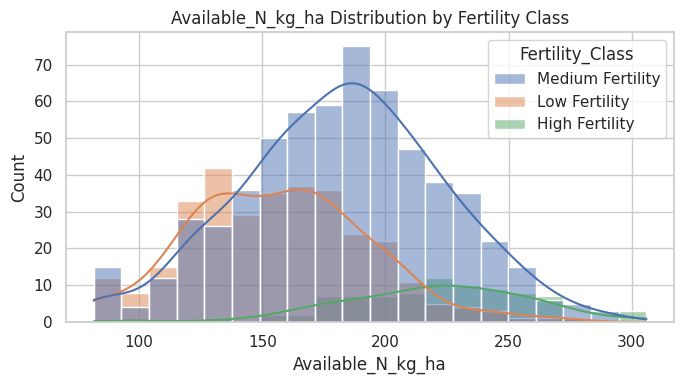

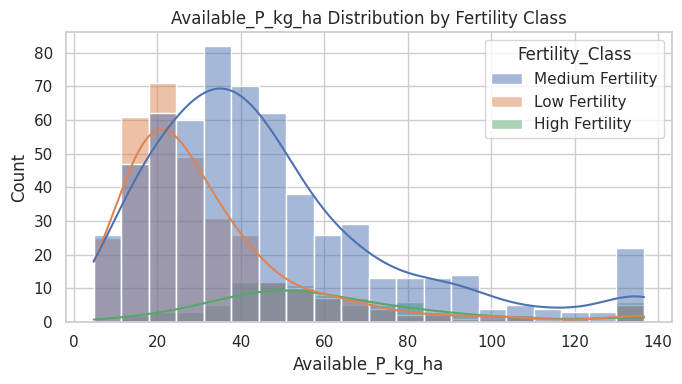

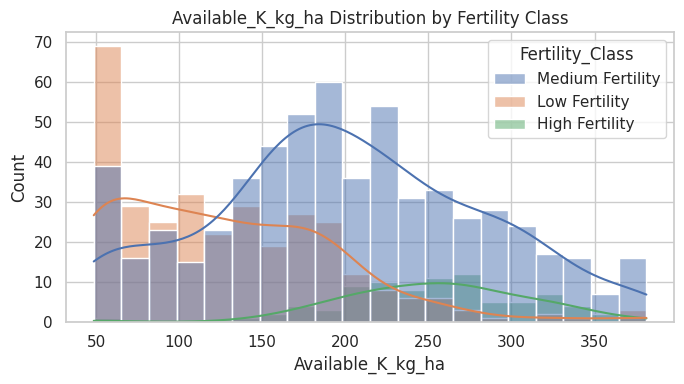

In [12]:
nutrients = ["Available_N_kg_ha", "Available_P_kg_ha", "Available_K_kg_ha"]
for col in nutrients:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=col, hue="Fertility_Class", bins=20, kde=True)
    plt.title(f"{col} Distribution by Fertility Class")
    plt.tight_layout()
    plt.show()

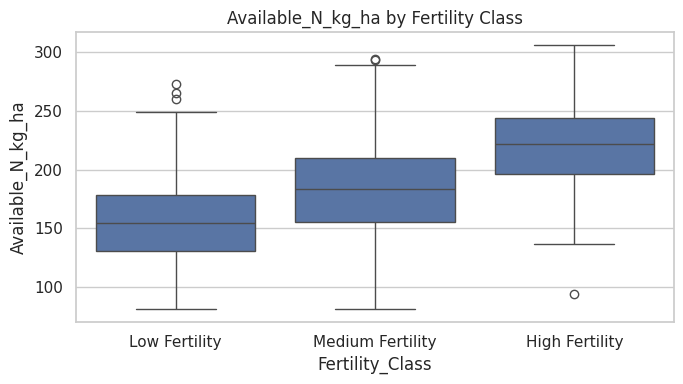

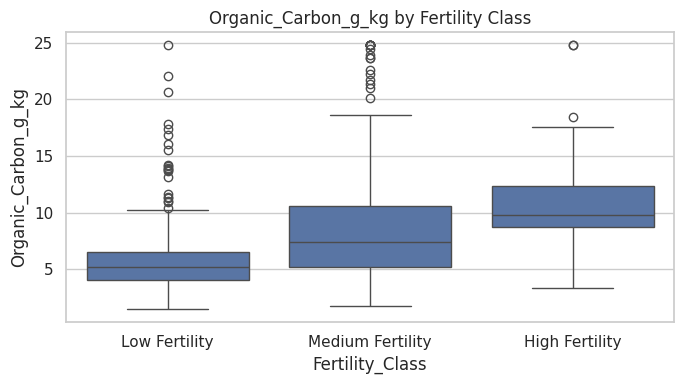

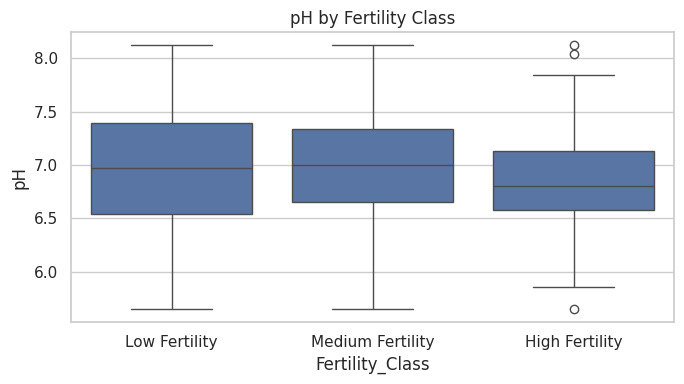

In [13]:
for col in ["Available_N_kg_ha", "Organic_Carbon_g_kg", "pH"]:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x="Fertility_Class", y=col, order=["Low Fertility", "Medium Fertility", "High Fertility"])
    plt.title(f"{col} by Fertility Class")
    plt.tight_layout()
    plt.show()

## 8. Correlation Analysis
The fertility score is shown for descriptive inspection only. It will not be used as a model input because it was used to derive the target class.

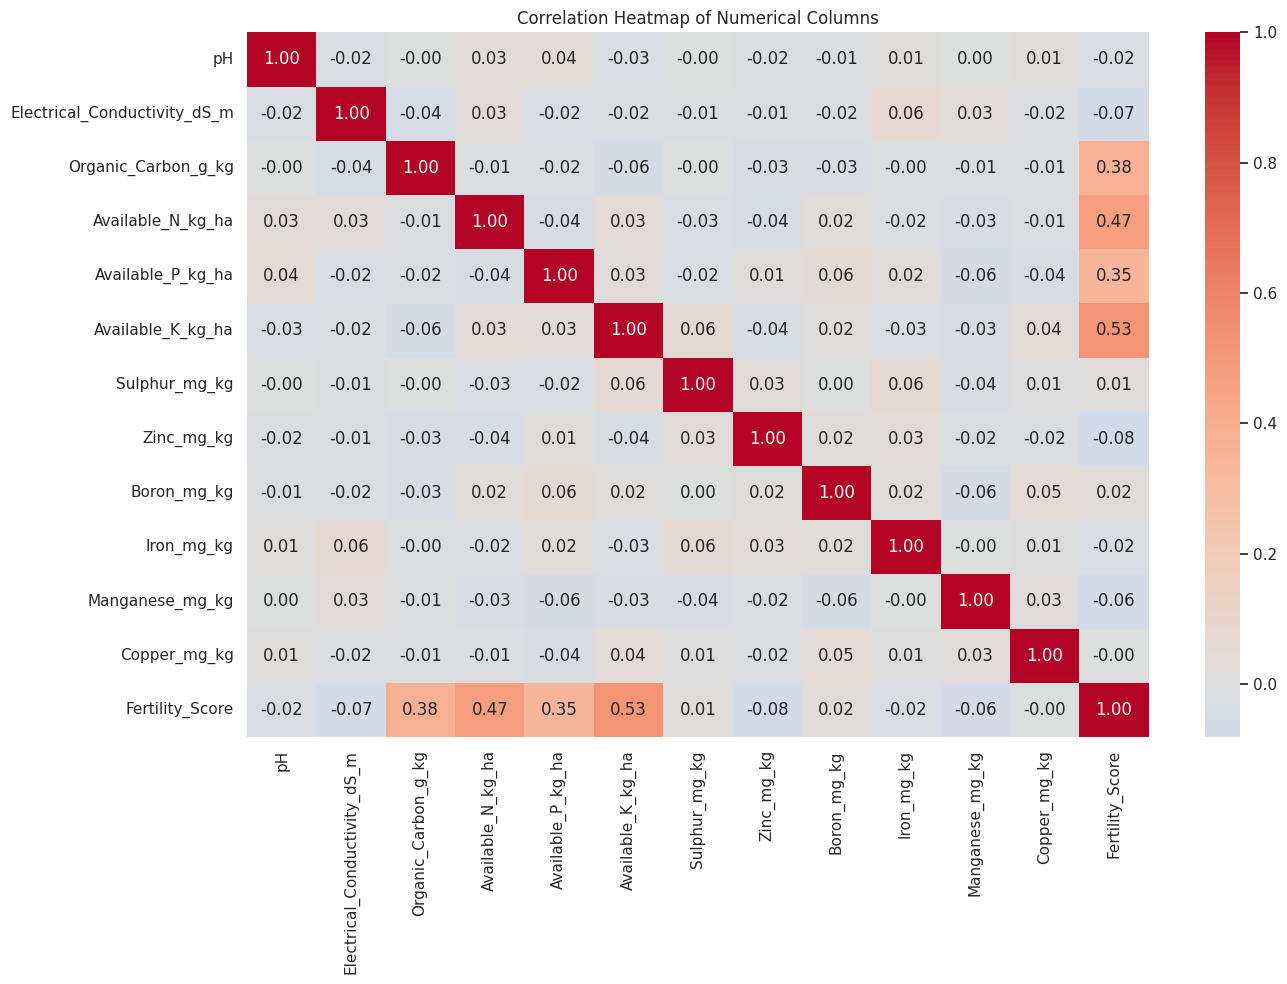

In [14]:
numeric_df = df.select_dtypes(include=np.number)
corr = numeric_df.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Numerical Columns")
plt.tight_layout()
plt.show()

## 9. Feature Selection
Use soil measurements only. Exclude `Fertility_Score` to reduce direct target leakage because the class label is derived from that score. The 12 numerical soil features below are selected as candidate inputs.

In [15]:
features = [
    "pH",
    "Electrical_Conductivity_dS_m",
    "Organic_Carbon_g_kg",
    "Available_N_kg_ha",
    "Available_P_kg_ha",
    "Available_K_kg_ha",
    "Sulphur_mg_kg",
    "Zinc_mg_kg",
    "Boron_mg_kg",
    "Iron_mg_kg",
    "Manganese_mg_kg",
    "Copper_mg_kg"
]

X = df[features].copy()
y = df["Fertility_Class"].copy()

print("Candidate input features:", len(features))
print("Target classes:", sorted(y.unique()))

Candidate input features: 12
Target classes: ['High Fertility', 'Low Fertility', 'Medium Fertility']


## 10. Train-Test Split
Split the data into 80% training and 20% test sets. Stratification keeps class proportions similar in both sets.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (800, 12)
Test set: (200, 12)


## 11. Feature Scaling and Model Setup
Scaling and feature selection are fitted inside each pipeline on training data only, helping avoid data leakage. Decision Tree and Random Forest do not require scaling, but the common pipeline keeps preprocessing comparable; scaling is especially useful for KNN and SVM.

In [17]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf")
}

pipelines = {}
for name, model in models.items():
    pipelines[name] = Pipeline([
        ("feature_selection", SelectKBest(score_func=mutual_info_classif, k=8)),
        ("scaler", StandardScaler()),
        ("classifier", model)
    ])

## 12. Train the Four Models

In [18]:
for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    print(f"{name}: training complete")

Decision Tree: training complete
Random Forest: training complete
KNN: training complete
SVM: training complete


## 13. Evaluate Models (Accuracy, Precision, Recall, F1)

In [19]:
results = []
predictions = {}

for name, pipeline in pipelines.items():
    y_pred = pipeline.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (Macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 Score (Macro)": f1_score(y_test, y_pred, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1 Score (Macro)", ascending=False).reset_index(drop=True)
display(results_df.round(4))

,Model,Accuracy,Precision (Macro),Recall (Macro),F1 Score (Macro)
0,SVM,0.880,0.9116,0.8391,0.8699
1,Random Forest,0.905,0.9400,0.7811,0.8281
2,Decision Tree,0.825,0.8070,0.7746,0.7883
3,KNN,0.785,0.8423,0.6922,0.7352


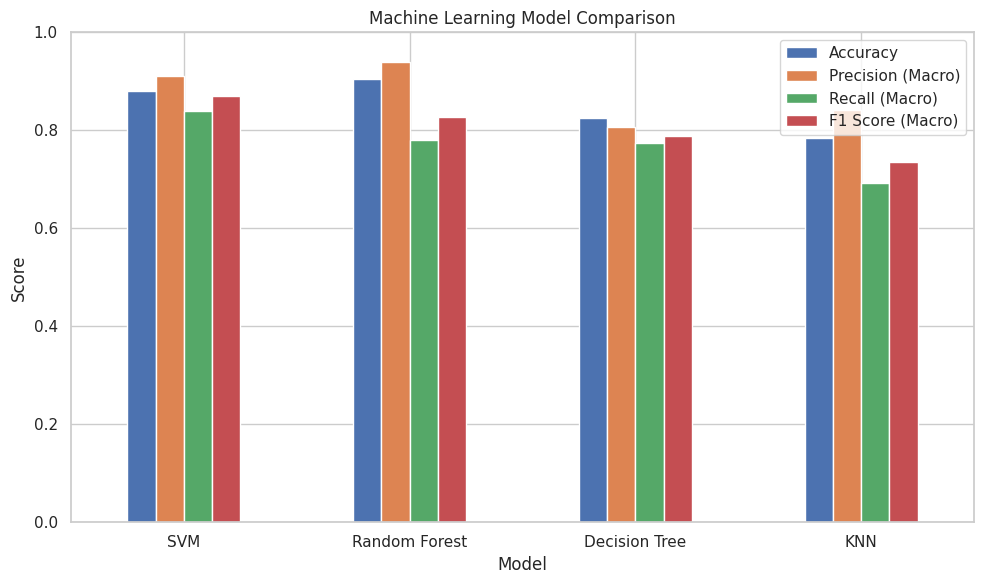

In [20]:
# Metric comparison plot
results_df.set_index("Model")[["Accuracy", "Precision (Macro)", "Recall (Macro)", "F1 Score (Macro)"]].plot(
    kind="bar", figsize=(10, 6)
)
plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 14. Confusion Matrices and Classification Reports

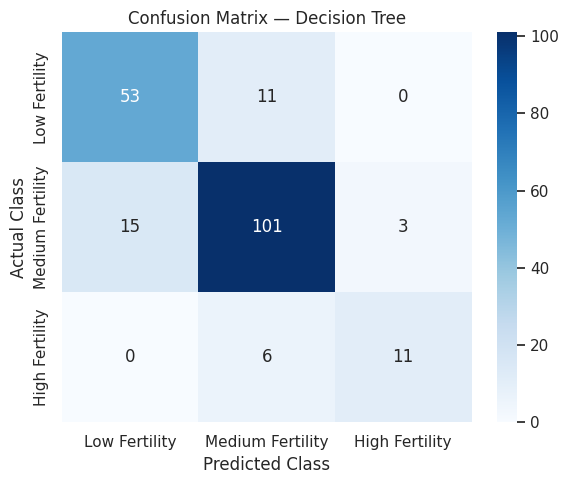

\nClassification Report — Decision Tree
                  precision    recall  f1-score   support

   Low Fertility       0.78      0.83      0.80        64
Medium Fertility       0.86      0.85      0.85       119
  High Fertility       0.79      0.65      0.71        17

        accuracy                           0.82       200
       macro avg       0.81      0.77      0.79       200
    weighted avg       0.83      0.82      0.82       200



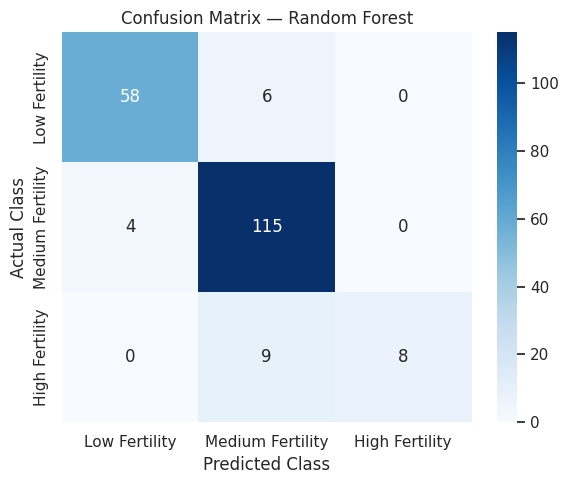

\nClassification Report — Random Forest
                  precision    recall  f1-score   support

   Low Fertility       0.94      0.91      0.92        64
Medium Fertility       0.88      0.97      0.92       119
  High Fertility       1.00      0.47      0.64        17

        accuracy                           0.91       200
       macro avg       0.94      0.78      0.83       200
    weighted avg       0.91      0.91      0.90       200



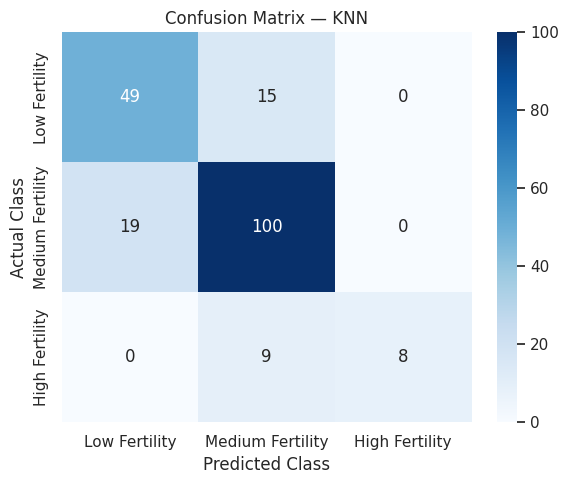

\nClassification Report — KNN
                  precision    recall  f1-score   support

   Low Fertility       0.72      0.77      0.74        64
Medium Fertility       0.81      0.84      0.82       119
  High Fertility       1.00      0.47      0.64        17

        accuracy                           0.79       200
       macro avg       0.84      0.69      0.74       200
    weighted avg       0.80      0.79      0.78       200



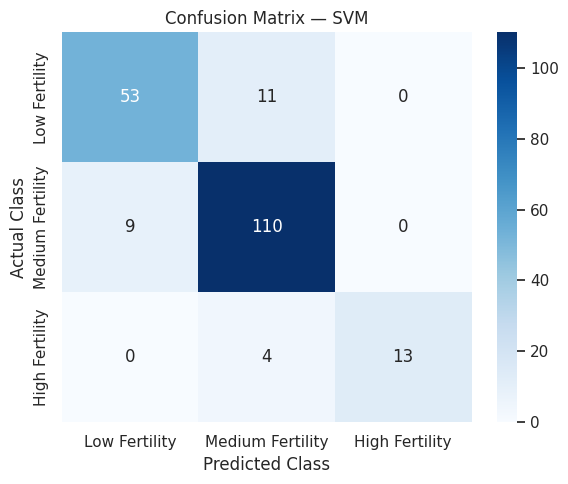

\nClassification Report — SVM
                  precision    recall  f1-score   support

   Low Fertility       0.85      0.83      0.84        64
Medium Fertility       0.88      0.92      0.90       119
  High Fertility       1.00      0.76      0.87        17

        accuracy                           0.88       200
       macro avg       0.91      0.84      0.87       200
    weighted avg       0.88      0.88      0.88       200



In [21]:
class_names = ["Low Fertility", "Medium Fertility", "High Fertility"]

for name, y_pred in predictions.items():
    cm = confusion_matrix(y_test, y_pred, labels=class_names)

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names, yticklabels=class_names
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.show()

    print(f"\\nClassification Report — {name}")
    print(classification_report(y_test, y_pred, labels=class_names, zero_division=0))

## 15. Select the Best Model
Macro F1-score is used as the main selection metric because it gives equal weight to each class. Accuracy is considered alongside class-wise reports and confusion matrices.

In [22]:
best_model_name = results_df.loc[0, "Model"]
best_model = pipelines[best_model_name]
best_pred = predictions[best_model_name]

print("Best model by Macro F1:", best_model_name)
print("Accuracy:", round(accuracy_score(y_test, best_pred), 4))
print("Macro Precision:", round(precision_score(y_test, best_pred, average="macro", zero_division=0), 4))
print("Macro Recall:", round(recall_score(y_test, best_pred, average="macro", zero_division=0), 4))
print("Macro F1:", round(f1_score(y_test, best_pred, average="macro", zero_division=0), 4))

Best model by Macro F1: SVM
Accuracy: 0.88
Macro Precision: 0.9116
Macro Recall: 0.8391
Macro F1: 0.8699


## 16. Feature Importance (Random Forest)
This analysis is from the Random Forest fitted inside its pipeline and only uses the features selected by that pipeline. Importance indicates predictive contribution within this model, not causation.

,Feature,Importance
4,Available_K_kg_ha,0.215315
2,Available_N_kg_ha,0.186759
1,Organic_Carbon_g_kg,0.181552
3,Available_P_kg_ha,0.170277
6,Manganese_mg_kg,0.063569
5,Iron_mg_kg,0.063069
0,Electrical_Conductivity_dS_m,0.063016
7,Copper_mg_kg,0.056443


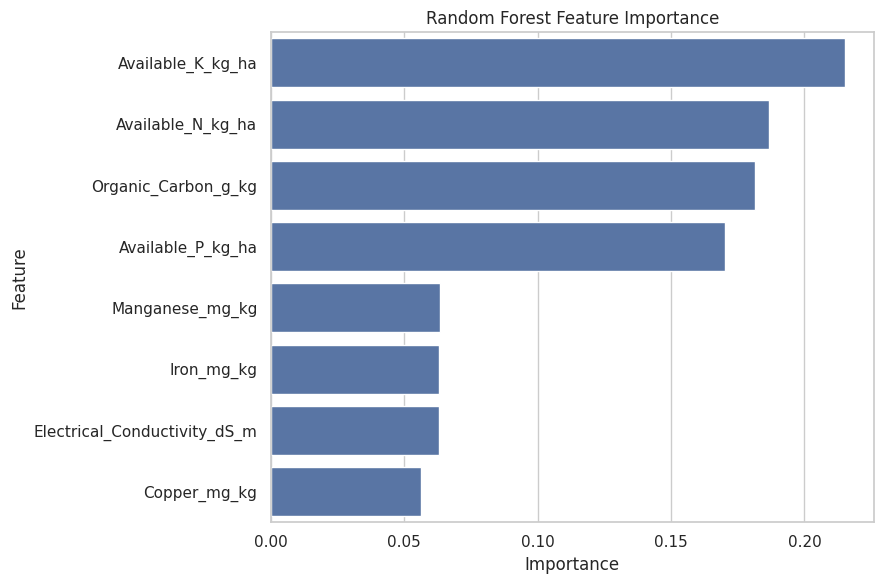

In [23]:
rf_pipeline = pipelines["Random Forest"]
rf_selector = rf_pipeline.named_steps["feature_selection"]
rf_model = rf_pipeline.named_steps["classifier"]
rf_selected_features = X_train.columns[rf_selector.get_support()]

importance_df = pd.DataFrame({
    "Feature": rf_selected_features,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(9, 6))
sns.barplot(data=importance_df, x="Importance", y="Feature")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

## 17. Predict a New Soil Sample
Enter measurements for the 12 candidate features. These example values are illustrative only. Use values with the same units as the dataset.

In [24]:
new_soil = pd.DataFrame([{
    "pH": 6.8,
    "Electrical_Conductivity_dS_m": 0.45,
    "Organic_Carbon_g_kg": 8.5,
    "Available_N_kg_ha": 250,
    "Available_P_kg_ha": 18,
    "Available_K_kg_ha": 180,
    "Sulphur_mg_kg": 12,
    "Zinc_mg_kg": 0.8,
    "Boron_mg_kg": 0.5,
    "Iron_mg_kg": 8,
    "Manganese_mg_kg": 7,
    "Copper_mg_kg": 0.6
}])[features]

predicted_class = best_model.predict(new_soil)[0]
print("Predicted Soil Fertility Class:", predicted_class)

Predicted Soil Fertility Class: Medium Fertility


## 18. Final Results Table

In [25]:
display(results_df.round(4))
print("Selected final model:", best_model_name)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1 Score (Macro)
0,SVM,0.880,0.9116,0.8391,0.8699
1,Random Forest,0.905,0.9400,0.7811,0.8281
2,Decision Tree,0.825,0.8070,0.7746,0.7883
3,KNN,0.785,0.8423,0.6922,0.7352


Selected final model: SVM


## 19. Conclusion (Automatically Filled)

In [26]:
best_row = results_df.iloc[0]

print(f'''
CONCLUSION

This project classified soil fertility into Low Fertility, Medium Fertility,
and High Fertility using a Machine Learning workflow.

Four algorithms were compared: Decision Tree, Random Forest, KNN, and SVM.
The best model by Macro F1-score was {best_row["Model"]}.

Its test metrics were:
Accuracy = {best_row["Accuracy"]:.4f}
Macro Precision = {best_row["Precision (Macro)"]:.4f}
Macro Recall = {best_row["Recall (Macro)"]:.4f}
Macro F1-score = {best_row["F1 Score (Macro)"]:.4f}

Data cleaning, EDA, visualizations, correlation analysis, feature selection,
training, evaluation, and prediction were completed.

Limitation: this is source-calibrated synthetic educational data, and
Fertility_Class is derived from soil parameters. Performance on this dataset
does not prove real-world agricultural accuracy.
''')


CONCLUSION

This project classified soil fertility into Low Fertility, Medium Fertility,
and High Fertility using a Machine Learning workflow.

Four algorithms were compared: Decision Tree, Random Forest, KNN, and SVM.
The best model by Macro F1-score was SVM.

Its test metrics were:
Accuracy = 0.8800
Macro Precision = 0.9116
Macro Recall = 0.8391
Macro F1-score = 0.8699

Data cleaning, EDA, visualizations, correlation analysis, feature selection,
training, evaluation, and prediction were completed.

Limitation: this is source-calibrated synthetic educational data, and
Fertility_Class is derived from soil parameters. Performance on this dataset
does not prove real-world agricultural accuracy.



## 20. Reproducibility Notes
- Random seed: `42` for the train/test split and models where applicable.
- Test size: 20%, stratified by target class.
- Feature selection: 8 features, performed inside each pipeline.
- Scaling: StandardScaler inside each pipeline.
- Primary comparison metric: Macro F1-score.
- Target leakage prevention: `Fertility_Score` is excluded from input features.

**Reminder:** Do not claim the model is validated on real farms or lab soil samples.